<a href="https://colab.research.google.com/github/steffanymarcellia046/ProjectETSMachineLearning/blob/main/Final_Code_EAS_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install prophet openpyxl
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


In [2]:
import pandas as pd
import os

# Sesuaikan dengan nama file yang tersedia di runtime.
candidate_files = [
    "/content/dataset kopi ML.xlsx"
]
file_path = next((p for p in candidate_files if os.path.exists(p)), None)

if file_path is None:
    raise FileNotFoundError(
        "File Excel tidak ditemukan. Unggah dataset kopi ML(1).xlsx "
        "atau Coffee Shop Sales.xlsx ke runtime."
    )

df = pd.read_excel(file_path, engine="openpyxl")
print("Dataset berhasil dimuat dari:", file_path)
display(df.head())


Dataset berhasil dimuat dari: /content/dataset kopi ML.xlsx


,transaction_id,transaction_date,transaction_time,transaction_qty,store_id,store_location,product_id,unit_price,product_category,product_type,product_detail
0,1,2023-01-01,07:06:11,2,5,Lower Manhattan,32,3.0,Coffee,Gourmet brewed coffee,Ethiopia Rg
1,2,2023-01-01,07:08:56,2,5,Lower Manhattan,57,3.1,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg
2,3,2023-01-01,07:14:04,2,5,Lower Manhattan,59,4.5,Drinking Chocolate,Hot chocolate,Dark chocolate Lg
3,4,2023-01-01,07:20:24,1,5,Lower Manhattan,22,2.0,Coffee,Drip coffee,Our Old Time Diner Blend Sm
4,5,2023-01-01,07:22:41,2,5,Lower Manhattan,57,3.1,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg


In [3]:
print("Ukuran dataset:", df.shape)
print("\nNama kolom:")
print(df.columns.tolist())

print("\nLima baris pertama:")
display(df.head())

print("\nInformasi data:")
df.info()

print("\nJumlah missing value:")
print(df.isnull().sum())

Ukuran dataset: (149116, 11)

Nama kolom:
['transaction_id', 'transaction_date', 'transaction_time', 'transaction_qty', 'store_id', 'store_location', 'product_id', 'unit_price', 'product_category', 'product_type', 'product_detail']

Lima baris pertama:


,transaction_id,transaction_date,transaction_time,transaction_qty,store_id,store_location,product_id,unit_price,product_category,product_type,product_detail
0,1,2023-01-01,07:06:11,2,5,Lower Manhattan,32,3.0,Coffee,Gourmet brewed coffee,Ethiopia Rg
1,2,2023-01-01,07:08:56,2,5,Lower Manhattan,57,3.1,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg
2,3,2023-01-01,07:14:04,2,5,Lower Manhattan,59,4.5,Drinking Chocolate,Hot chocolate,Dark chocolate Lg
3,4,2023-01-01,07:20:24,1,5,Lower Manhattan,22,2.0,Coffee,Drip coffee,Our Old Time Diner Blend Sm
4,5,2023-01-01,07:22:41,2,5,Lower Manhattan,57,3.1,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg



Informasi data:
<class 'pandas.DataFrame'>
RangeIndex: 149116 entries, 0 to 149115
Data columns (total 11 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   transaction_id    149116 non-null  int64         
 1   transaction_date  149116 non-null  datetime64[us]
 2   transaction_time  149116 non-null  object        
 3   transaction_qty   149116 non-null  int64         
 4   store_id          149116 non-null  int64         
 5   store_location    149116 non-null  str           
 6   product_id        149116 non-null  int64         
 7   unit_price        149116 non-null  float64       
 8   product_category  149116 non-null  str           
 9   product_type      149116 non-null  str           
 10  product_detail    149116 non-null  str           
dtypes: datetime64[us](1), float64(1), int64(4), object(1), str(4)
memory usage: 19.8+ MB

Jumlah missing value:
transaction_id      0
transaction_date    0
transaction

Filter data

In [4]:
# Mengubah tanggal ke format datetime
df["transaction_date"] = pd.to_datetime(
    df["transaction_date"],
    errors="coerce"
)

# Mengubah kuantitas menjadi numerik
df["transaction_qty"] = pd.to_numeric(
    df["transaction_qty"],
    errors="coerce"
)

# Menghapus baris yang tanggal atau kuantitasnya tidak valid
df = df.dropna(
    subset=["transaction_date", "transaction_qty", "store_location"]
)

# Memastikan kuantitas tidak negatif
df = df[df["transaction_qty"] >= 0]

# Memilih satu lokasi
df_lokasi = df[
    df["store_location"] == "Hell's Kitchen"
].copy()

print("Jumlah baris setelah filter:", len(df_lokasi))
print("Tanggal awal:", df_lokasi["transaction_date"].min())
print("Tanggal akhir:", df_lokasi["transaction_date"].max())

display(df_lokasi.head())

Jumlah baris setelah filter: 50735
Tanggal awal: 2023-01-01 00:00:00
Tanggal akhir: 2023-06-30 00:00:00


,transaction_id,transaction_date,transaction_time,transaction_qty,store_id,store_location,product_id,unit_price,product_category,product_type,product_detail
17,18,2023-01-01,08:00:18,1,8,Hell's Kitchen,42,2.50,Tea,Brewed herbal tea,Lemon Grass Rg
18,19,2023-01-01,08:00:39,2,8,Hell's Kitchen,59,4.50,Drinking Chocolate,Hot chocolate,Dark chocolate Lg
19,20,2023-01-01,08:11:45,1,8,Hell's Kitchen,61,4.75,Drinking Chocolate,Hot chocolate,Sustainably Grown Organic Lg
20,21,2023-01-01,08:17:27,2,8,Hell's Kitchen,33,3.50,Coffee,Gourmet brewed coffee,Ethiopia Lg
23,24,2023-01-01,08:29:38,1,8,Hell's Kitchen,56,2.55,Tea,Brewed Chai tea,Spicy Eye Opener Chai Rg


Penjualan per hari

In [5]:
# Menjumlahkan kuantitas penjualan setiap hari
data_harian = (
    df_lokasi
    .groupby("transaction_date")["transaction_qty"]
    .sum()
    .reset_index()
)

# Menyesuaikan nama kolom untuk Prophet
data_harian = data_harian.rename(
    columns={
        "transaction_date": "ds",
        "transaction_qty": "y"
    }
)

# Membuat rentang tanggal harian yang lengkap
rentang_tanggal = pd.date_range(
    start=data_harian["ds"].min(),
    end=data_harian["ds"].max(),
    freq="D"
)

data_harian = (
    data_harian
    .set_index("ds")
    .reindex(rentang_tanggal, fill_value=0)
    .rename_axis("ds")
    .reset_index()
)

print("Jumlah data harian:", len(data_harian))
print("\nData harian:")
display(data_harian.head(10))

print("\nStatistik deskriptif:")
display(data_harian["y"].describe())

Jumlah data harian: 181

Data harian:


,ds,y
0,2023-01-01,270
1,2023-01-02,272
2,2023-01-03,295
3,2023-01-04,256
4,2023-01-05,235
5,2023-01-06,256
6,2023-01-07,323
7,2023-01-08,277
8,2023-01-09,272
9,2023-01-10,273



Statistik deskriptif:


count    181.000000
mean     396.337017
std      129.535462
min      195.000000
25%      290.000000
50%      363.000000
75%      483.000000
max      769.000000
Name: y, dtype: float64

EDA

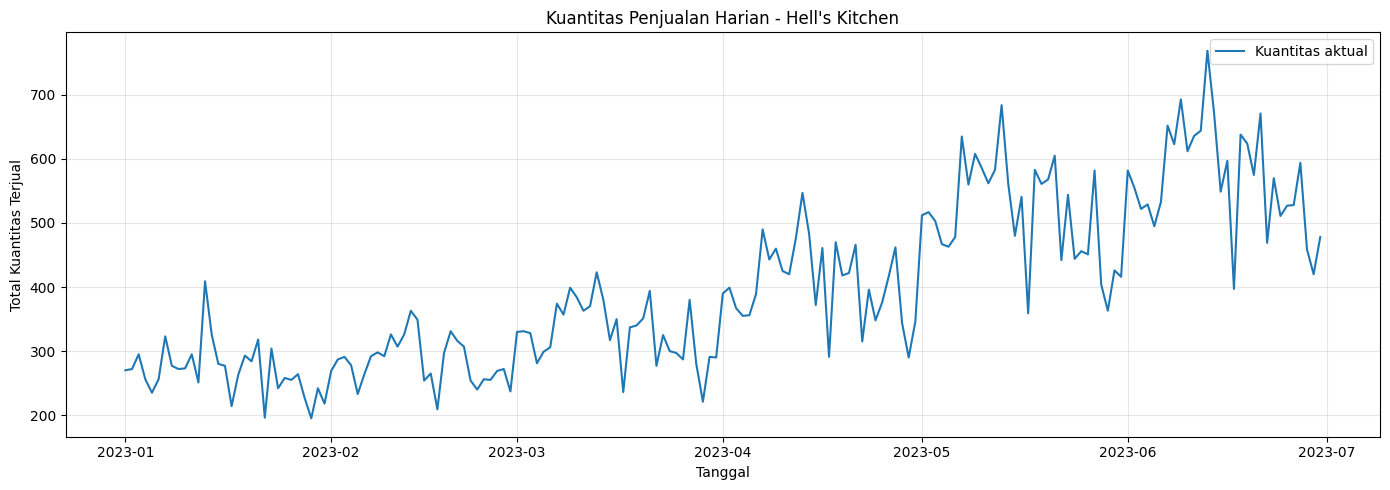

In [6]:
plt.figure(figsize=(14, 5))

plt.plot(
    data_harian["ds"],
    data_harian["y"],
    label="Kuantitas aktual"
)

plt.title("Kuantitas Penjualan Harian - Hell's Kitchen")
plt.xlabel("Tanggal")
plt.ylabel("Total Kuantitas Terjual")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Pola penjualan berdasarkan hari

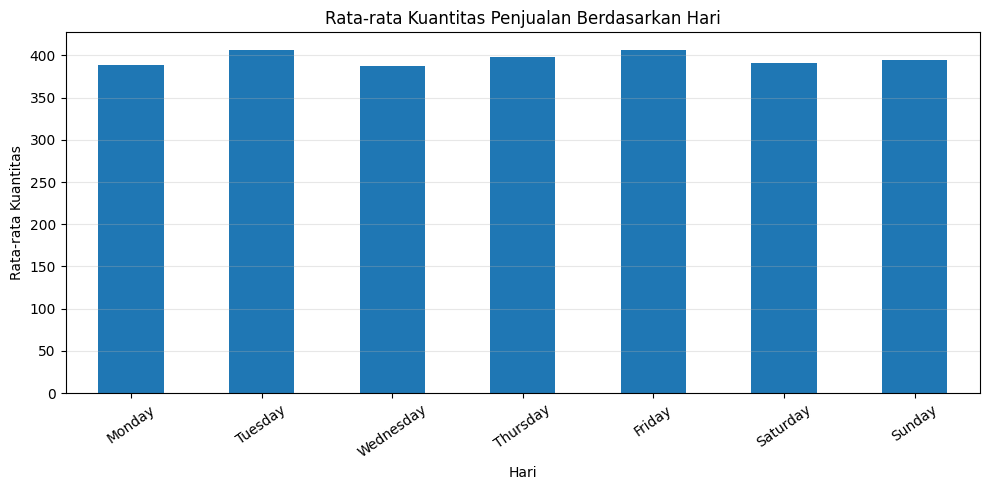

In [7]:
data_harian["nama_hari"] = (
    data_harian["ds"].dt.day_name()
)

urutan_hari = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

rata_hari = (
    data_harian
    .groupby("nama_hari")["y"]
    .mean()
    .reindex(urutan_hari)
)

plt.figure(figsize=(10, 5))
rata_hari.plot(kind="bar")

plt.title("Rata-rata Kuantitas Penjualan Berdasarkan Hari")
plt.xlabel("Hari")
plt.ylabel("Rata-rata Kuantitas")
plt.xticks(rotation=35)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Pemisahan data training dan testing

In [8]:
# Pastikan urutan tanggal sudah benar
data_harian = data_harian.sort_values("ds").reset_index(drop=True)

# Pembagian berdasarkan waktu
split_index = int(len(data_harian) * 0.80)

train = data_harian.iloc[:split_index][["ds", "y"]].copy()
test = data_harian.iloc[split_index:][["ds", "y"]].copy()

print("Jumlah data training:", len(train))
print("Jumlah data testing:", len(test))

print("\nPeriode training:")
print(train["ds"].min(), "sampai", train["ds"].max())

print("\nPeriode testing:")
print(test["ds"].min(), "sampai", test["ds"].max())

Jumlah data training: 144
Jumlah data testing: 37

Periode training:
2023-01-01 00:00:00 sampai 2023-05-24 00:00:00

Periode testing:
2023-05-25 00:00:00 sampai 2023-06-30 00:00:00


Fungsi evaluasi

In [9]:
import pandas as pd
import numpy as np
from prophet import Prophet

def evaluasi_model(aktual, prediksi):
    aktual = np.asarray(aktual, dtype=float)
    prediksi = np.maximum(
        np.asarray(prediksi, dtype=float), 0
    )

    error = aktual - prediksi

    mae = np.mean(np.abs(error))
    rmse = np.sqrt(np.mean(error ** 2))

    # MAPE tidak terdefinisi jika nilai aktual = 0
    mask = aktual != 0
    mape = (
        np.mean(np.abs(error[mask] / aktual[mask])) * 100
        if mask.any() else np.nan
    )

    penyebut = np.abs(aktual) + np.abs(prediksi)
    smape_per_baris = np.divide(
        2 * np.abs(error),
        penyebut,
        out=np.zeros_like(penyebut, dtype=float),
        where=penyebut != 0
    )
    smape = np.mean(smape_per_baris) * 100

    return {
        "MAE": mae,
        "RMSE": rmse,
        "MAPE (%)": mape,
        "SMAPE (%)": smape
    }

Latih prophet baseline dan prophet jittering

In [10]:
# Salin dan rapikan data
train_asli = train[["ds", "y"]].copy()
validasi = test[["ds", "y"]].copy()

train_asli["ds"] = pd.to_datetime(train_asli["ds"])
validasi["ds"] = pd.to_datetime(validasi["ds"])

train_asli = train_asli.sort_values("ds").reset_index(drop=True)
validasi = validasi.sort_values("ds").reset_index(drop=True)

# MODEL A: Prophet dengan data training asli
model_baseline = Prophet(
    yearly_seasonality=False,
    weekly_seasonality=True,
    daily_seasonality=False,
    seasonality_mode="additive",
    interval_width=0.95
)

model_baseline.fit(train_asli)

pred_baseline = model_baseline.predict(
    validasi[["ds"]]
)["yhat"].to_numpy()

# MODEL B: Prophet dengan noise injection pada training
rng = np.random.default_rng(42)

# Besar noise: 2% dari simpangan baku target training
besar_noise = 0.02 * train_asli["y"].std()

train_jitter = train_asli.copy()
noise = rng.normal(
    loc=0,
    scale=besar_noise,
    size=len(train_jitter)
)

# Penjualan tidak boleh negatif
train_jitter["y"] = np.maximum(
    train_jitter["y"].to_numpy() + noise,
    0
)

model_jitter = Prophet(
    yearly_seasonality=False,
    weekly_seasonality=True,
    daily_seasonality=False,
    seasonality_mode="additive",
    interval_width=0.95
)

model_jitter.fit(train_jitter)

pred_jitter = model_jitter.predict(
    validasi[["ds"]]
)["yhat"].to_numpy()

# Evaluasi kedua model pada data validasi yang sama
hasil_perbandingan = pd.DataFrame([
    {
        "Model": "Prophet Baseline",
        **evaluasi_model(validasi["y"], pred_baseline)
    },
    {
        "Model": "Prophet + Jittering",
        **evaluasi_model(validasi["y"], pred_jitter)
    }
])

display(hasil_perbandingan.round(4))

,Model,MAE,RMSE,MAPE (%),SMAPE (%)
0,Prophet Baseline,87.2320,104.5342,17.6828,15.9248
1,Prophet + Jittering,87.8597,105.4581,17.8453,16.0231


Hasil prophet baseline & prophet jittering

In [11]:
metrik = ["MAE", "RMSE", "MAPE (%)", "SMAPE (%)"]

hasil = hasil_perbandingan.set_index("Model")

print("Perbandingan perubahan nilai error:")
for kolom in metrik:
    baseline = hasil.loc["Prophet Baseline", kolom]
    jitter = hasil.loc["Prophet + Jittering", kolom]

    perubahan = jitter - baseline

    print(
        f"{kolom}: baseline={baseline:.4f}, "
        f"jitter={jitter:.4f}, "
        f"perubahan={perubahan:+.4f}"
    )

Perbandingan perubahan nilai error:
MAE: baseline=87.2320, jitter=87.8597, perubahan=+0.6277
RMSE: baseline=104.5342, jitter=105.4581, perubahan=+0.9239
MAPE (%): baseline=17.6828, jitter=17.8453, perubahan=+0.1625
SMAPE (%): baseline=15.9248, jitter=16.0231, perubahan=+0.0983


Siapkan library dan data penjualan

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from prophet import Prophet

# Ubah tanggal menjadi format datetime
df["transaction_date"] = pd.to_datetime(
    df["transaction_date"]
)

# Pilih lokasi Hell's Kitchen
df = df[
    df["store_location"] == "Hell's Kitchen"
].copy()

# Agregasi jumlah penjualan per hari
data_harian = (
    df.groupby("transaction_date")["transaction_qty"]
    .sum()
    .reset_index()
)

# Sesuaikan nama kolom untuk Prophet
data_harian = data_harian.rename(
    columns={
        "transaction_date": "ds",
        "transaction_qty": "y"
    }
)

# Pastikan tanggal berurutan
data_harian = data_harian.sort_values(
    "ds"
).reset_index(drop=True)

# Tampilkan data
display(data_harian.head())
print("Jumlah data harian:", len(data_harian))
print("Periode:", data_harian["ds"].min(),
      "sampai", data_harian["ds"].max())

,ds,y
0,2023-01-01,270
1,2023-01-02,272
2,2023-01-03,295
3,2023-01-04,256
4,2023-01-05,235


Jumlah data harian: 181
Periode: 2023-01-01 00:00:00 sampai 2023-06-30 00:00:00


Pembagian data training dan testing

In [13]:
data_harian = (
    data_harian.sort_values("ds")
    .reset_index(drop=True)
)

split_index = int(len(data_harian) * 0.80)

train = data_harian.iloc[:split_index][
    ["ds", "y"]
].copy()

test = data_harian.iloc[split_index:][
    ["ds", "y"]
].copy()

print("Jumlah data training:", len(train))
print("Jumlah data testing:", len(test))

print(
    "\nPeriode training:",
    train["ds"].min(), "sampai", train["ds"].max()
)

print(
    "Periode testing:",
    test["ds"].min(), "sampai", test["ds"].max()
)

Jumlah data training: 144
Jumlah data testing: 37

Periode training: 2023-01-01 00:00:00 sampai 2023-05-24 00:00:00
Periode testing: 2023-05-25 00:00:00 sampai 2023-06-30 00:00:00


Melatih Prophet Baseline

In [14]:
model_baseline = Prophet(
    yearly_seasonality=False,
    weekly_seasonality=True,
    daily_seasonality=False,
    seasonality_mode="additive",
    interval_width=0.95
)

model_baseline.fit(train)

# Prediksi pada tanggal testing
forecast_baseline = model_baseline.predict(
    test[["ds"]]
)

prediksi_baseline = np.maximum(
    forecast_baseline["yhat"].to_numpy(),
    0
)

print("Model Prophet baseline selesai dilatih.")

Model Prophet baseline selesai dilatih.


Visualisasi hasil prediksi

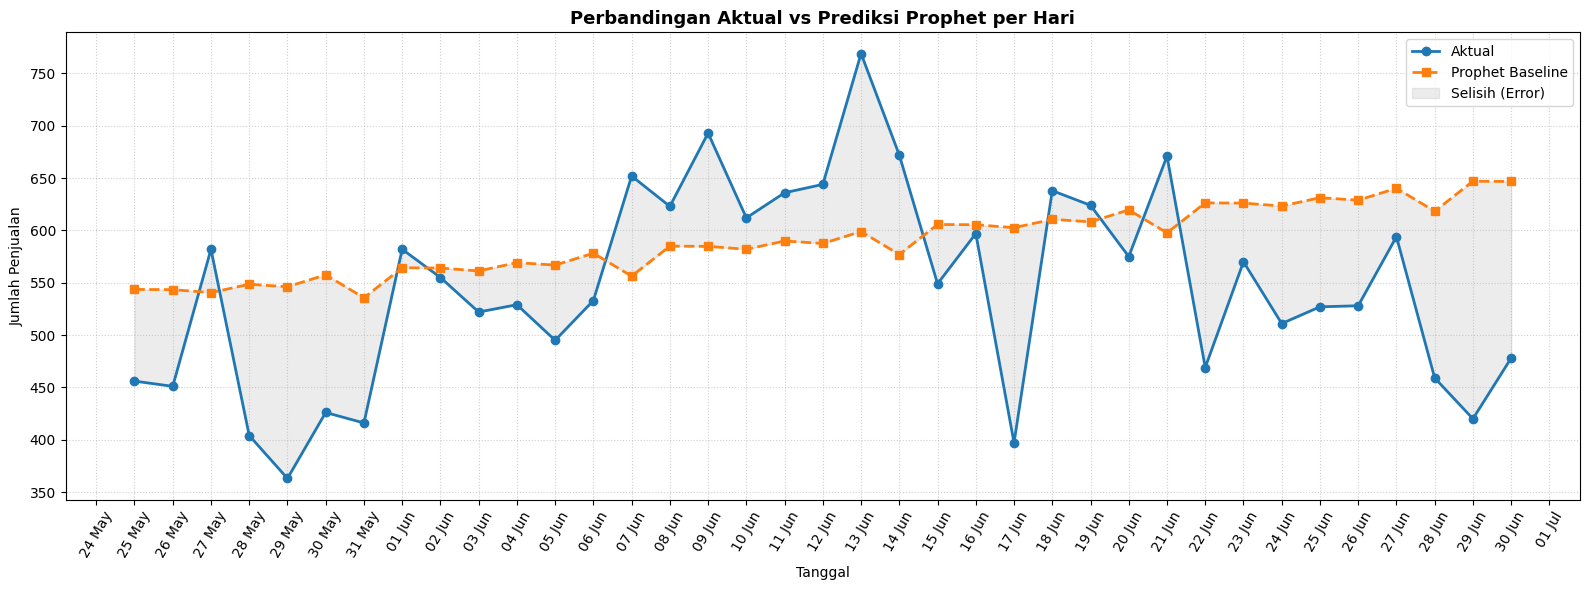

In [15]:
import matplotlib.dates as mdates

plt.figure(figsize=(16, 6))

# Plot Aktual dengan marker jelas
plt.plot(
    test["ds"],
    test["y"],
    label="Aktual",
    marker="o",
    linewidth=2,
    color="#1f77b4"
)

# Plot Prediksi Prophet dengan marker & garis putus-putus agar mudah dibedakan
plt.plot(
    test["ds"],
    prediksi_baseline,
    label="Prophet Baseline",
    marker="s",
    linestyle="--",
    linewidth=2,
    color="#ff7f0e"
)

# Arsiran selisih antara Aktual dan Prediksi per hari
plt.fill_between(
    test["ds"],
    test["y"],
    prediksi_baseline,
    color="gray",
    alpha=0.15,
    label="Selisih (Error)"
)

# Menampilkan label tanggal setiap hari secara eksplisit di sumbu X
ax = plt.gca()
ax.xaxis.set_major_locator(mdates.DayLocator(interval=1))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))

plt.title("Perbandingan Aktual vs Prediksi Prophet per Hari", fontsize=13, fontweight="bold")
plt.xlabel("Tanggal")
plt.ylabel("Jumlah Penjualan")
plt.legend()
plt.grid(True, linestyle=":", alpha=0.6)
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()

Evaluasi Prophet

In [16]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Definisi fungsi MAPE dan SMAPE
def calculate_mape(y_true, y_pred):
    return np.mean(np.abs((y_true - y_pred) / np.maximum(1e-8, np.abs(y_true)))) * 100

def calculate_smape(y_true, y_pred):
    return 100 / len(y_true) * np.sum(2 * np.abs(y_pred - y_true) / (np.abs(y_true) + np.abs(y_pred) + 1e-8))

# 2. Fungsi untuk menghasilkan semua metrik evaluasi
def evaluate_all_metrics(y_true, y_pred):
    return {
        'MAE': mean_absolute_error(y_true, y_pred),
        'MSE': mean_squared_error(y_true, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
        'MAPE (%)': calculate_mape(y_true, y_pred),
        'SMAPE (%)': calculate_smape(y_true, y_pred),
        'R2-Score': r2_score(y_true, y_pred)
    }

# 3. Definisikan y_true menggunakan data aktual dari test set
y_true = test['y'].values

# 4. Hitung metrik untuk Prophet Murni menggunakan variabel yang benar
metrics_prophet = evaluate_all_metrics(y_true, prediksi_baseline)

# 5. Buat tabel perbandingan yang rapi
comparison_table = pd.DataFrame(
    [metrics_prophet],
    index=['Prophet Murni']
)

display(comparison_table.round(4))

,MAE,MSE,RMSE,MAPE (%),SMAPE (%),R2-Score
Prophet Murni,87.232,10927.4044,104.5342,17.6828,15.9248,-0.2273


QRF

In [17]:
!pip install optuna quantile-forest

In [18]:
!pip install -U shap scikit-learn quantile-forest

In [19]:
!pip install --quiet --force-reinstall "scikit-learn>=1.6.0" "shap>=0.45.1" "quantile-forest>=1.5.0"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import optuna
import shap
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor
from quantile_forest import RandomForestQuantileRegressor

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.
bigframes 2.51.0 requires python-dateutil<3,>=2.8.2, but you have python-dateutil 4.0.0 which is incompatible.
google-cloud-bigquery 3.47.0 requires python-dateutil<3.0.0,>=2.8.2, but you have python-dateutil 4.0.0 which is incompatible.
holidays 0.108 requires python-dateutil<3,>=2.9.0.post0, but you have python-dateutil 4.0.0 which is incompatible.
betterproto 2.0.0b7 requires python-dateutil<3.0,>=2.8, but you have python-dateutil 4.0.0 which is incompatible.
numba 0.64.0 requires numpy<2.5,>=1.22, but you have numpy 2.5.5 which is incompatible.
ibis-framework 9.5.0 requires python-dateutil<3,>=2.8.2, but you have python-dateutil 4.0.0 which is incompatible.


## Implementasi Prophet + QRF, fitur periode waktu, SHAP, dan prediksi 7 hari

Versi ini menggunakan pola tujuh hari terakhir untuk membentuk fitur operasional masa depan. Prediksi multi-hari dilakukan secara rekursif: residual hasil prediksi QRF pada satu hari menjadi riwayat untuk hari berikutnya. Fitur operasional masa depan diambil dari profil tujuh hari historis terakhir berdasarkan hari dalam minggu.

**Pencegahan data leakage:** tidak menggunakan `bfill()` untuk mengisi lag; fitur operasional training memakai lag tujuh hari; prediksi holdout tidak membaca residual aktual pada periode testing; residual QRF diprediksi secara rekursif. Evaluasi Optuna menggunakan `TimeSeriesSplit` dengan interpretasi rolling one-step-ahead, sedangkan holdout diuji sebagai prediksi multi-hari rekursif.

**Catatan interpretasi:** SHAP menjelaskan pengaruh fitur terhadap residual relatif yang dipelajari QRF, bukan hubungan sebab-akibat. Prediksi tujuh hari merupakan prediksi kuantitas total semua kategori produk untuk Hell's Kitchen.


/tmp/ipykernel_26906/826194164.py:33: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  parsed_time = pd.to_datetime(


Jumlah observasi harian: 181
Periode: 2023-01-01 00:00:00 s.d. 2023-06-30 00:00:00

Contoh fitur operasional:


,ds,pagi_ratio,siang_ratio,sore_ratio,malam_ratio,pct_bakery,basket_size,avg_unit_price
0,2023-01-01,0.203704,0.385185,0.240741,0.170370,0.066667,1.467391,3.177446
1,2023-01-02,0.272059,0.356618,0.216912,0.154412,0.084559,1.394872,3.072051
2,2023-01-03,0.223729,0.315254,0.322034,0.138983,0.098305,1.398104,3.111137
3,2023-01-04,0.210938,0.382812,0.183594,0.222656,0.062500,1.505882,3.090588
4,2023-01-05,0.246809,0.285106,0.285106,0.182979,0.072340,1.398810,3.084524



Training: 144 2023-01-01 00:00:00 s.d. 2023-05-24 00:00:00
Testing : 37 2023-05-25 00:00:00 s.d. 2023-06-30 00:00:00


/tmp/ipykernel_26906/826194164.py:203: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  out["dayofweek"] = out["ds"].dt.dayofweek



Jumlah baris training QRF setelah fitur lag: 143
Parameter QRF terbaik: {'n_estimators': 175, 'max_depth': 9, 'min_samples_split': 8, 'min_samples_leaf': 4}
MAE CV residual relatif: 0.079988


/tmp/ipykernel_26906/826194164.py:342: Pandas4Warning: Timestamp.dayofweek is deprecated and will be removed in a future version. Use Timestamp.day_of_week instead.
  "dayofweek": date.dayofweek,
/tmp/ipykernel_26906/826194164.py:342: Pandas4Warning: Timestamp.dayofweek is deprecated and will be removed in a future version. Use Timestamp.day_of_week instead.
  "dayofweek": date.dayofweek,
/tmp/ipykernel_26906/826194164.py:342: Pandas4Warning: Timestamp.dayofweek is deprecated and will be removed in a future version. Use Timestamp.day_of_week instead.
  "dayofweek": date.dayofweek,
/tmp/ipykernel_26906/826194164.py:342: Pandas4Warning: Timestamp.dayofweek is deprecated and will be removed in a future version. Use Timestamp.day_of_week instead.
  "dayofweek": date.dayofweek,
/tmp/ipykernel_26906/826194164.py:342: Pandas4Warning: Timestamp.dayofweek is deprecated and will be removed in a future version. Use Timestamp.day_of_week instead.
  "dayofweek": date.dayofweek,
/tmp/ipykernel_26906


=== EVALUASI HOLDOUT ===


,Model,MAE,RMSE,MAPE (%),SMAPE (%),R2
0,Prophet,87.2320,104.5342,17.6828,15.9248,-0.2273
1,Prophet + QRF,48.2077,67.3375,9.4995,8.8306,0.4907


,ds,y,prediksi_prophet,prediksi_ensemble,prediksi_bawah,prediksi_atas
144,2023-05-25,456,543.630321,452.345560,417.155591,534.311693
145,2023-05-26,451,543.404265,452.157463,416.508024,524.248270
146,2023-05-27,582,540.595157,449.820052,414.354901,521.538188
147,2023-05-28,404,548.543645,430.149383,383.417199,487.651538
148,2023-05-29,363,546.179838,449.728153,381.764962,519.756619


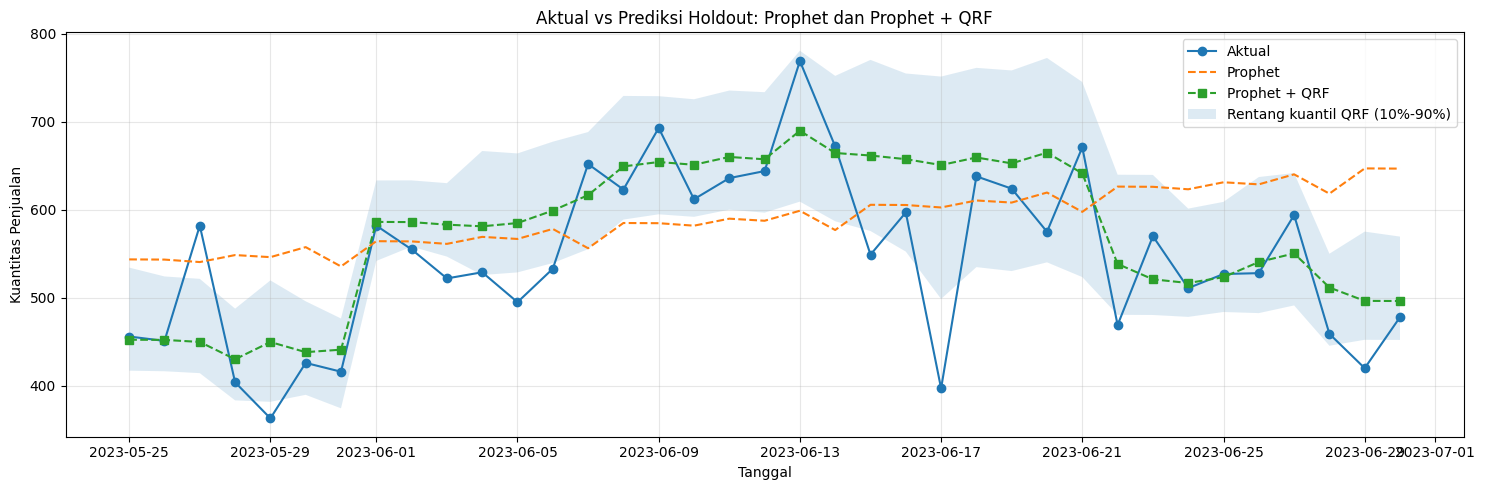

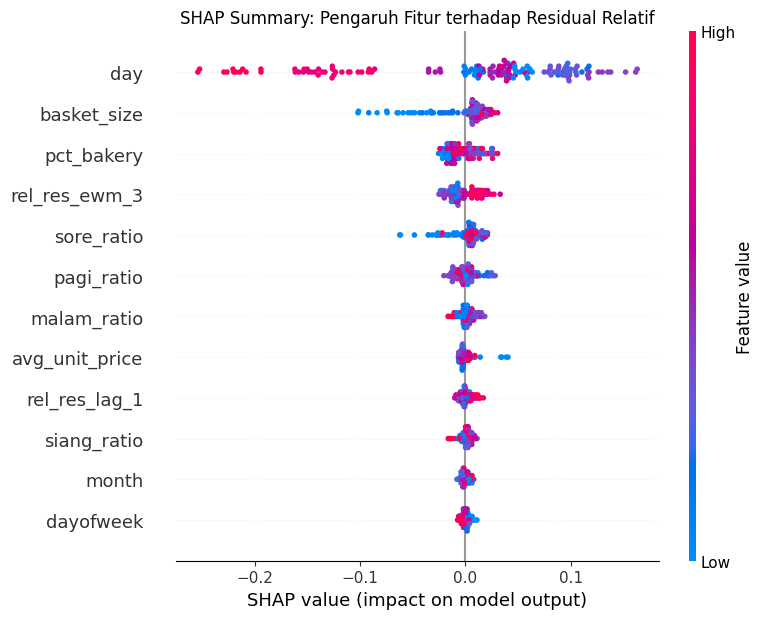


=== PERINGKAT PENGARUH FITUR BERDASARKAN SHAP ===


,Fitur,Mean_ABS_SHAP
2,day,0.086400
10,basket_size,0.018440
9,pct_bakery,0.012147
4,rel_res_ewm_3,0.011267
7,sore_ratio,0.010286
5,pagi_ratio,0.006799
8,malam_ratio,0.005243
11,avg_unit_price,0.004035
3,rel_res_lag_1,0.003821
6,siang_ratio,0.003158


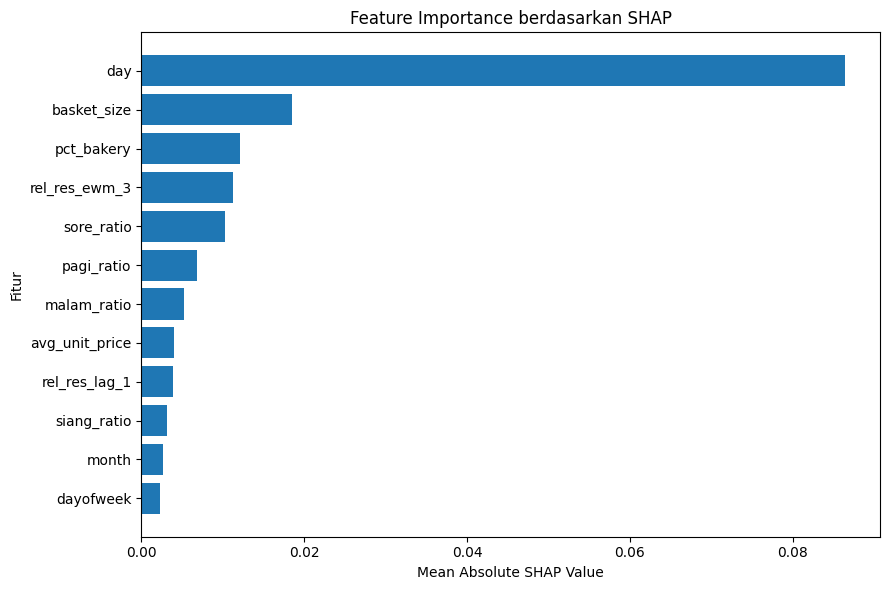

/tmp/ipykernel_26906/826194164.py:203: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  out["dayofweek"] = out["ds"].dt.dayofweek
/tmp/ipykernel_26906/826194164.py:342: Pandas4Warning: Timestamp.dayofweek is deprecated and will be removed in a future version. Use Timestamp.day_of_week instead.
  "dayofweek": date.dayofweek,
/tmp/ipykernel_26906/826194164.py:342: Pandas4Warning: Timestamp.dayofweek is deprecated and will be removed in a future version. Use Timestamp.day_of_week instead.
  "dayofweek": date.dayofweek,
/tmp/ipykernel_26906/826194164.py:342: Pandas4Warning: Timestamp.dayofweek is deprecated and will be removed in a future version. Use Timestamp.day_of_week instead.
  "dayofweek": date.dayofweek,
/tmp/ipykernel_26906/826194164.py:342: Pandas4Warning: Timestamp.dayofweek is deprecated and will be removed in a future version. Use Timestamp.day_of_week instead.
  "dayofweek": date.dayofweek,



=== PREDIKSI ENSEMBLE 7 HARI KE DEPAN ===


/tmp/ipykernel_26906/826194164.py:342: Pandas4Warning: Timestamp.dayofweek is deprecated and will be removed in a future version. Use Timestamp.day_of_week instead.
  "dayofweek": date.dayofweek,
/tmp/ipykernel_26906/826194164.py:342: Pandas4Warning: Timestamp.dayofweek is deprecated and will be removed in a future version. Use Timestamp.day_of_week instead.
  "dayofweek": date.dayofweek,
/tmp/ipykernel_26906/826194164.py:342: Pandas4Warning: Timestamp.dayofweek is deprecated and will be removed in a future version. Use Timestamp.day_of_week instead.
  "dayofweek": date.dayofweek,
/tmp/ipykernel_26906/826194164.py:601: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(2)


,Tanggal,Prediksi_Prophet,Batas_Bawah_10%,Prediksi_Ensemble,Batas_Atas_90%
0,2023-07-01,590.22,557.63,614.51,671.74
1,2023-07-02,600.72,579.07,625.43,683.68
2,2023-07-03,595.35,562.48,622.31,684.17
3,2023-07-04,613.47,572.21,636.22,698.19
4,2023-07-05,594.41,550.68,627.63,685.31
5,2023-07-06,605.02,560.51,638.84,703.30
6,2023-07-07,613.89,575.11,674.17,732.85


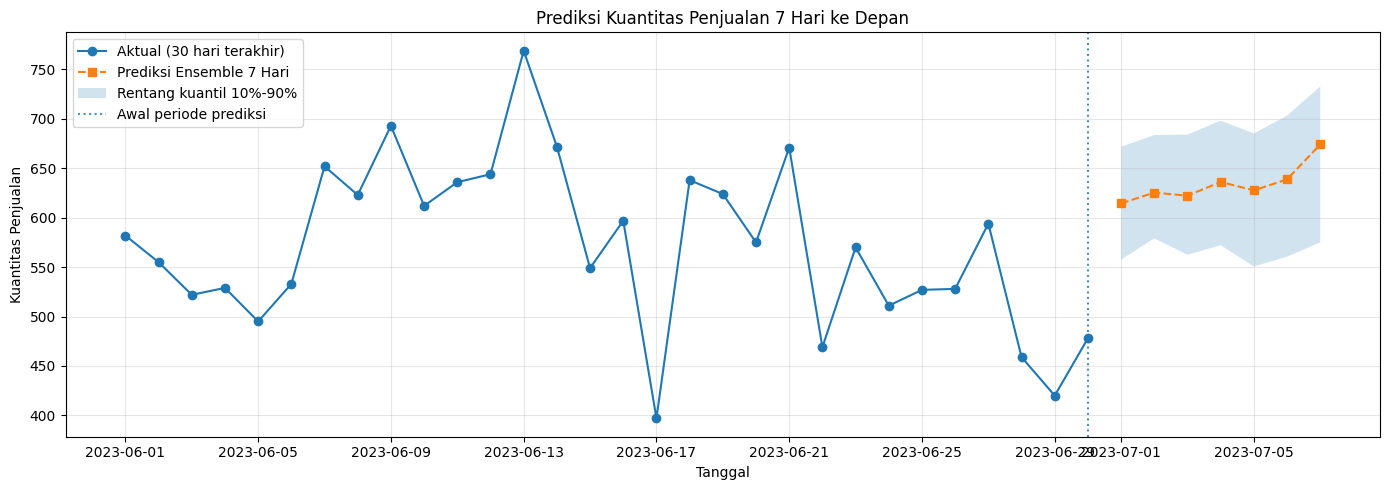

Prediksi dimulai: 2023-07-01 00:00:00 hingga 2023-07-07 00:00:00


In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import optuna
import shap

from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor
from quantile_forest import RandomForestQuantileRegressor

# =============================================================================
# 0. PERSIAPAN DATA
# =============================================================================
# Gunakan df_lokasi dari cell preprocessing sebelumnya agar data mentah
# tidak tertimpa oleh proses feature engineering.
df_raw = df_lokasi.copy()

df_raw["transaction_date"] = pd.to_datetime(
    df_raw["transaction_date"], errors="coerce"
)
df_raw["transaction_qty"] = pd.to_numeric(
    df_raw["transaction_qty"], errors="coerce"
)
df_raw = df_raw.dropna(
    subset=["transaction_date", "transaction_time", "transaction_qty"]
)
df_raw = df_raw[df_raw["transaction_qty"] >= 0].copy()
df_raw["ds"] = df_raw["transaction_date"].dt.normalize()

# Jam transaksi dibuat menjadi menit sejak 00.00.
# Format ini lebih toleran terhadap variasi representasi jam pada Excel.
parsed_time = pd.to_datetime(
    df_raw["transaction_time"].astype(str),
    errors="coerce"
)
df_raw["minute_of_day"] = (
    parsed_time.dt.hour * 60 + parsed_time.dt.minute
)
df_raw = df_raw.dropna(subset=["minute_of_day"]).copy()
df_raw["minute_of_day"] = df_raw["minute_of_day"].astype(int)

# Target harian: total kuantitas semua kategori produk.
data_harian_qrf = (
    df_raw.groupby("ds", as_index=False)["transaction_qty"]
    .sum()
    .rename(columns={"transaction_qty": "y"})
    .sort_values("ds")
    .reset_index(drop=True)
)

# Data sumber Hell's Kitchen memiliki transaksi pada seluruh tanggal
# dalam rentang observasi. Reindex tetap dipakai untuk memastikan kalender rapi.
calendar = pd.date_range(
    data_harian_qrf["ds"].min(),
    data_harian_qrf["ds"].max(),
    freq="D"
)
data_harian_qrf = (
    data_harian_qrf.set_index("ds")
    .reindex(calendar, fill_value=0)
    .rename_axis("ds")
    .reset_index()
)

print("Jumlah observasi harian:", len(data_harian_qrf))
print("Periode:", data_harian_qrf["ds"].min(), "s.d.", data_harian_qrf["ds"].max())


# =============================================================================
# 1. EKSTRAKSI FITUR OPERASIONAL PER HARI
# =============================================================================
def extract_operational_features(df_input):
    d = df_input.copy()

    # Batas periode:
    # Pagi  08:00-10:59 | Siang 11:00-14:59
    # Sore  15:00-17:59 | Malam 18:00-20:00
    m = d["minute_of_day"]
    q = d["transaction_qty"]

    d["qty_pagi"] = np.where(m.between(8*60, 10*60+59), q, 0)
    d["qty_siang"] = np.where(m.between(11*60, 14*60+59), q, 0)
    d["qty_sore"] = np.where(m.between(15*60, 17*60+59), q, 0)
    d["qty_malam"] = np.where(m.between(18*60, 20*60), q, 0)

    if "product_category" in d.columns:
        d["qty_bakery"] = np.where(
            d["product_category"].astype(str).str.casefold() == "bakery",
            q, 0
        )
    else:
        d["qty_bakery"] = 0

    # ID transaksi dihitung unik bila kolom tersedia.
    if "transaction_id" in d.columns:
        daily = d.groupby("ds").agg(
            total_qty=("transaction_qty", "sum"),
            n_tx=("transaction_id", "nunique"),
            pagi_qty=("qty_pagi", "sum"),
            siang_qty=("qty_siang", "sum"),
            sore_qty=("qty_sore", "sum"),
            malam_qty=("qty_malam", "sum"),
            bakery_qty=("qty_bakery", "sum")
        ).reset_index()
    else:
        daily = d.groupby("ds").agg(
            total_qty=("transaction_qty", "sum"),
            n_tx=("transaction_qty", "size"),
            pagi_qty=("qty_pagi", "sum"),
            siang_qty=("qty_siang", "sum"),
            sore_qty=("qty_sore", "sum"),
            malam_qty=("qty_malam", "sum"),
            bakery_qty=("qty_bakery", "sum")
        ).reset_index()

    # Harga rata-rata transaksi harian, bila tersedia.
    if "unit_price" in d.columns:
        avg_price = d.groupby("ds")["unit_price"].mean()
        daily["avg_unit_price"] = daily["ds"].map(avg_price)
    else:
        daily["avg_unit_price"] = np.nan

    denominator = daily["total_qty"].replace(0, np.nan)
    for period in ["pagi", "siang", "sore", "malam"]:
        daily[f"{period}_ratio"] = daily[f"{period}_qty"] / denominator

    daily["pct_bakery"] = daily["bakery_qty"].replace(0, np.nan) / denominator
    daily["basket_size"] = (
        daily["total_qty"] / daily["n_tx"].replace(0, np.nan)
    )

    feature_cols_operasional = [
        "pagi_ratio", "siang_ratio", "sore_ratio", "malam_ratio",
        "pct_bakery", "basket_size", "avg_unit_price"
    ]
    return daily[["ds"] + feature_cols_operasional].sort_values("ds").reset_index(drop=True)


daily_op_features = extract_operational_features(df_raw)

print("\nContoh fitur operasional:")
display(daily_op_features.head())


# =============================================================================
# 2. PEMBAGIAN DATA TRAINING DAN TESTING SECARA KRONOLOGIS
# =============================================================================
data_harian_qrf = data_harian_qrf.sort_values("ds").reset_index(drop=True)
split_index = int(len(data_harian_qrf) * 0.80)

train_qrf = data_harian_qrf.iloc[:split_index][["ds", "y"]].copy()
test_qrf = data_harian_qrf.iloc[split_index:][["ds", "y"]].copy()

print("\nTraining:", len(train_qrf), train_qrf["ds"].min(), "s.d.", train_qrf["ds"].max())
print("Testing :", len(test_qrf), test_qrf["ds"].min(), "s.d.", test_qrf["ds"].max())


# =============================================================================
# 3. PROPHET BASELINE UNTUK PERIODE TRAINING DAN TESTING
# =============================================================================
prophet_train = Prophet(
    yearly_seasonality=False,
    weekly_seasonality=True,
    daily_seasonality=False,
    seasonality_mode="additive",
    interval_width=0.95
)
prophet_train.fit(train_qrf)

forecast_train = prophet_train.predict(train_qrf[["ds"]])
forecast_test = prophet_train.predict(test_qrf[["ds"]])

# Residual relatif pada training menjadi target QRF.
train_base = np.maximum(forecast_train["yhat"].to_numpy(), 1.0)
train_residual = (
    train_qrf["y"].to_numpy() - train_base
) / train_base

test_base = np.maximum(forecast_test["yhat"].to_numpy(), 0.0)


# =============================================================================
# 4. FITUR HISTORIS TANPA DATA LEAKAGE
# =============================================================================
FEATURE_COLS = [
    "dayofweek", "month", "day",
    "rel_res_lag_1", "rel_res_ewm_3",
    "pagi_ratio", "siang_ratio", "sore_ratio", "malam_ratio",
    "pct_bakery", "basket_size", "avg_unit_price"
]

def make_training_features(train_data, residual_values, operational_data):
    """
    Untuk tanggal t:
    - residual lag dan EWM hanya memakai residual sampai t-1;
    - fitur operasional memakai profil pada t-1 (pola satu hari sebelumnya).
    Baris awal yang belum memiliki riwayat dibuang, bukan bfill.
    """
    out = train_data[["ds", "y"]].copy().reset_index(drop=True)
    out["rel_residual"] = np.asarray(residual_values, dtype=float)

    out["dayofweek"] = out["ds"].dt.dayofweek
    out["month"] = out["ds"].dt.month
    out["day" ] = out["ds"].dt.day

    out["rel_res_lag_1"] = out["rel_residual"].shift(1)
    out["rel_res_ewm_3"] = (
        out["rel_residual"].shift(1)
        .ewm(span=3, adjust=False, min_periods=1)
        .mean()
    )

    op = operational_data.sort_values("ds").reset_index(drop=True).copy()
    op = op.set_index("ds")

    # Ambil fitur operasional pada tanggal yang sama satu hari sebelumnya.
    op_lag1 = op.reindex(out["ds"] - pd.Timedelta(days=1))
    op_lag1.index = out.index

    for col in [
        "pagi_ratio", "siang_ratio", "sore_ratio", "malam_ratio",
        "pct_bakery", "basket_size", "avg_unit_price"
    ]:
        out[col] = op_lag1[col].to_numpy()

    # Tidak menggunakan bfill: baris awal tanpa histori dibuang.
    out = out.dropna(subset=FEATURE_COLS + ["rel_residual"]).reset_index(drop=True)
    return out


train_features = make_training_features(
    train_qrf, train_residual, daily_op_features
)

X_train = train_features[FEATURE_COLS].astype(float)
y_train_residual = train_features["rel_residual"].astype(float)

if len(X_train) < 30:
    raise ValueError(
        "Data training QRF terlalu sedikit setelah pembentukan fitur lag. "
        "Pertimbangkan proporsi split atau fitur lag yang digunakan."
    )

print("\nJumlah baris training QRF setelah fitur lag:", len(X_train))


# =============================================================================
# 5. OPTIMASI HIPERPARAMETER QRF DENGAN TIME SERIES CROSS-VALIDATION
# =============================================================================
# CV ini menilai prediksi satu-langkah-ke-depan (rolling one-step).
# Pada tiap titik validasi, histori aktual yang telah terjadi diasumsikan tersedia.
tscv = TimeSeriesSplit(n_splits=3)

def objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 250, step=25),
        "max_depth": trial.suggest_int("max_depth", 6, 18),
        "min_samples_split": trial.suggest_int("min_samples_split", 2, 8),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 4),
        "random_state": 42,
        "n_jobs": -1
    }

    fold_mae = []
    for tr_idx, val_idx in tscv.split(X_train):
        model = RandomForestQuantileRegressor(**params)
        model.fit(X_train.iloc[tr_idx], y_train_residual.iloc[tr_idx])

        pred = model.predict(
            X_train.iloc[val_idx], quantiles=[0.5]
        ).reshape(-1)

        fold_mae.append(
            mean_absolute_error(y_train_residual.iloc[val_idx], pred)
        )

    return float(np.mean(fold_mae))


optuna.logging.set_verbosity(optuna.logging.WARNING)
study = optuna.create_study(direction="minimize")
study.optimize(objective, n_trials=30)

best_params = study.best_params.copy()
best_qrf = RandomForestQuantileRegressor(
    **best_params, random_state=42, n_jobs=-1
)
best_qrf.fit(X_train, y_train_residual)

print("Parameter QRF terbaik:", best_params)
print("MAE CV residual relatif:", round(study.best_value, 6))


# =============================================================================
# 6. FUNGSI PREDIKSI REKURSIF MULTI-HARI
# =============================================================================
def get_last_operational_profile(operational_data):
    """
    Mengambil fitur operasional dari satu hari terakhir
    yang tersedia sebagai asumsi fitur untuk prediksi berikutnya.
    """
    hist = operational_data.sort_values("ds").copy()

    op_cols = [
        "pagi_ratio", "siang_ratio", "sore_ratio", "malam_ratio",
        "pct_bakery", "basket_size", "avg_unit_price"
    ]
    return hist.iloc[-1][op_cols].astype(float)


def recursive_qrf_forecast(
    dates,
    prophet_base,
    fitted_qrf,
    residual_history,
    last_operational_profile
):
    """
    Prediksi multi-hari secara rekursif.
    Residual hari berikutnya menggunakan prediksi median QRF sebelumnya,
    bukan residual aktual yang belum diketahui.
    """
    residual_hist = list(np.asarray(residual_history, dtype=float))
    rows = []

    op_cols = [
        "pagi_ratio", "siang_ratio", "sore_ratio", "malam_ratio",
        "pct_bakery", "basket_size", "avg_unit_price"
    ]

    for i, date in enumerate(pd.to_datetime(dates)):
        date = pd.Timestamp(date)

        # Statistik residual yang tersedia hanya sampai hari sebelumnya.
        lag1 = residual_hist[-1]
        ewm3 = pd.Series(residual_hist).ewm(
            span=3, adjust=False, min_periods=1
        ).mean().iloc[-1]

        row = {
            "dayofweek": date.dayofweek,
            "month": date.month,
            "day": date.day,
            "rel_res_lag_1": lag1,
            "rel_res_ewm_3": ewm3
        }

        # Pola fitur operasional terakhir, dipetakan.
        for col in op_cols:
            row[col] = float(last_operational_profile[col])

        X_next = pd.DataFrame([row], columns=FEATURE_COLS).astype(float)
        q = fitted_qrf.predict(
            X_next, quantiles=[0.1, 0.5, 0.9]
        ).reshape(-1)

        base = max(float(prophet_base[i]), 0.0)
        lower = max(0.0, base * (1.0 + q[0]))
        median = max(0.0, base * (1.0 + q[1]))
        upper = max(0.0, base * (1.0 + q[2]))

        rows.append({
            "ds": date,
            "yhat_prophet": base,
            "prediksi_bawah": lower,
            "prediksi_ensemble": median,
            "prediksi_atas": upper,
            "prediksi_residual_rel": q[1]
        })

        # Penting: gunakan residual hasil prediksi untuk langkah berikutnya.
        residual_hist.append(float(q[1]))

    return pd.DataFrame(rows)


# =============================================================================
# 7. EVALUASI HOLDOUT: PREDIKSI REKURSIF TANPA AKSES KE AKTUAL TEST
# =============================================================================
# Operasional pattern hanya diambil dari data training.
op_train = daily_op_features[
    daily_op_features["ds"].isin(train_qrf["ds"])
].copy()
last_op_test = get_last_operational_profile(op_train)

test_recursive = recursive_qrf_forecast(
    dates=test_qrf["ds"],
    prophet_base=test_base,
    fitted_qrf=best_qrf,
    residual_history=train_residual,
    last_operational_profile=last_op_test
)

y_true_test = test_qrf["y"].to_numpy()
y_pred_test = test_recursive["prediksi_ensemble"].to_numpy()

def evaluate_forecast(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.maximum(np.asarray(y_pred, dtype=float), 0)

    error = y_true - y_pred
    nonzero = y_true != 0

    mape = (
        np.mean(np.abs(error[nonzero] / y_true[nonzero])) * 100
        if nonzero.any() else np.nan
    )

    smape_den = np.abs(y_true) + np.abs(y_pred)
    smape_each = np.divide(
        2 * np.abs(error),
        smape_den,
        out=np.zeros_like(smape_den, dtype=float),
        where=smape_den != 0
    )

    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAPE (%)": mape,
        "SMAPE (%)": np.mean(smape_each) * 100,
        "R2": r2_score(y_true, y_pred)
    }


# Prophet murni dan ensemble dievaluasi pada rentang tanggal yang sama.
hasil_evaluasi = pd.DataFrame([
    {
        "Model": "Prophet",
        **evaluate_forecast(y_true_test, test_base)
    },
    {
        "Model": "Prophet + QRF",
        **evaluate_forecast(y_true_test, y_pred_test)
    }
])

print("\n=== EVALUASI HOLDOUT ===")
display(hasil_evaluasi.round(4))

hasil_test = test_qrf[["ds", "y"]].copy()
hasil_test["prediksi_prophet"] = test_base
hasil_test["prediksi_ensemble"] = y_pred_test
hasil_test["prediksi_bawah"] = test_recursive["prediksi_bawah"].to_numpy()
hasil_test["prediksi_atas"] = test_recursive["prediksi_atas"].to_numpy()
display(hasil_test.head())


# =============================================================================
# 8. VISUALISASI AKTUAL VS PREDIKSI HOLDOUT
# =============================================================================
plt.figure(figsize=(15, 5))
plt.plot(hasil_test["ds"], hasil_test["y"], marker="o", label="Aktual")
plt.plot(
    hasil_test["ds"], hasil_test["prediksi_prophet"],
    linestyle="--", label="Prophet"
)
plt.plot(
    hasil_test["ds"], hasil_test["prediksi_ensemble"],
    marker="s", linestyle="--", label="Prophet + QRF"
)
plt.fill_between(
    hasil_test["ds"],
    hasil_test["prediksi_bawah"],
    hasil_test["prediksi_atas"],
    alpha=0.15,
    label="Rentang kuantil QRF (10%-90%)"
)
plt.title("Aktual vs Prediksi Holdout: Prophet dan Prophet + QRF")
plt.xlabel("Tanggal")
plt.ylabel("Kuantitas Penjualan")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# =============================================================================
# 9. SHAP FEATURE IMPORTANCE
# =============================================================================
# SHAP menjelaskan pengaruh fitur terhadap prediksi residual relatif QRF,
# bukan pengaruh kausal terhadap total penjualan.
# Gunakan RandomForest surrogate agar interpretasi TreeSHAP kompatibel.
rf_surrogate = RandomForestRegressor(
    n_estimators=300,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)
rf_surrogate.fit(X_train, y_train_residual)

X_shap = X_train.sample(
    n=min(200, len(X_train)),
    random_state=42
)

explainer = shap.TreeExplainer(rf_surrogate)
shap_values = explainer.shap_values(X_shap)

# Grafik ringkasan arah dan besarnya kontribusi fitur.
shap.summary_plot(shap_values, X_shap, show=False)
plt.title("SHAP Summary: Pengaruh Fitur terhadap Residual Relatif")
plt.tight_layout()
plt.show()

# Peringkat global berdasarkan rata-rata nilai absolut SHAP.
shap_importance = pd.DataFrame({
    "Fitur": X_shap.columns,
    "Mean_ABS_SHAP": np.abs(shap_values).mean(axis=0)
}).sort_values("Mean_ABS_SHAP", ascending=False)

print("\n=== PERINGKAT PENGARUH FITUR BERDASARKAN SHAP ===")
display(shap_importance.round(6))

plt.figure(figsize=(9, 6))
plot_imp = shap_importance.sort_values("Mean_ABS_SHAP", ascending=True)
plt.barh(plot_imp["Fitur"], plot_imp["Mean_ABS_SHAP"])
plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Fitur")
plt.title("Feature Importance berdasarkan SHAP")
plt.tight_layout()
plt.show()


# =============================================================================
# 10. LATIH ULANG PADA SELURUH DATA DAN PREDIKSI 7 HARI KE DEPAN
# =============================================================================
# Untuk penggunaan setelah evaluasi, model akhir dilatih ulang memakai
# seluruh data historis yang tersedia.
final_data = data_harian_qrf[["ds", "y"]].copy().reset_index(drop=True)

prophet_final = Prophet(
    yearly_seasonality=False,
    weekly_seasonality=True,
    daily_seasonality=False,
    seasonality_mode="additive",
    interval_width=0.95
)
prophet_final.fit(final_data)

forecast_final_train = prophet_final.predict(final_data[["ds"]])
final_base_train = np.maximum(
    forecast_final_train["yhat"].to_numpy(), 1.0
)
final_residual = (
    final_data["y"].to_numpy() - final_base_train
) / final_base_train

final_features = make_training_features(
    final_data, final_residual, daily_op_features
)
X_final = final_features[FEATURE_COLS].astype(float)
y_final_residual = final_features["rel_residual"].astype(float)

qrf_final = RandomForestQuantileRegressor(
    **best_params, random_state=42, n_jobs=-1
)
qrf_final.fit(X_final, y_final_residual)

# Buat tujuh tanggal kalender setelah tanggal terakhir.
future_dates = pd.date_range(
    start=final_data["ds"].max() + pd.Timedelta(days=1),
    periods=7,
    freq="D"
)
future_prophet = prophet_final.predict(
    pd.DataFrame({"ds": future_dates})
)
future_base = np.maximum(
    future_prophet["yhat"].to_numpy(), 0.0
)

final_op_pattern = get_last_operational_profile(
    daily_op_features
)

prediksi_7_hari = recursive_qrf_forecast(
    dates=future_dates,
    prophet_base=future_base,
    fitted_qrf=qrf_final,
    residual_history=final_residual,
    last_operational_profile=final_op_pattern
)

prediksi_7_hari = prediksi_7_hari.rename(columns={
    "ds": "Tanggal",
    "yhat_prophet": "Prediksi_Prophet",
    "prediksi_bawah": "Batas_Bawah_10%",
    "prediksi_ensemble": "Prediksi_Ensemble",
    "prediksi_atas": "Batas_Atas_90%"
})

print("\n=== PREDIKSI ENSEMBLE 7 HARI KE DEPAN ===")
display(
    prediksi_7_hari[
        [
            "Tanggal", "Prediksi_Prophet",
            "Batas_Bawah_10%", "Prediksi_Ensemble", "Batas_Atas_90%"
        ]
    ].round(2)
)


# =============================================================================
# 11. VISUALISASI PREDIKSI 7 HARI KE DEPAN
# =============================================================================
last_history = final_data.tail(30)

plt.figure(figsize=(14, 5))
plt.plot(
    last_history["ds"], last_history["y"],
    marker="o", label="Aktual (30 hari terakhir)"
)
plt.plot(
    prediksi_7_hari["Tanggal"],
    prediksi_7_hari["Prediksi_Ensemble"],
    marker="s", linestyle="--", label="Prediksi Ensemble 7 Hari"
)
plt.fill_between(
    prediksi_7_hari["Tanggal"],
    prediksi_7_hari["Batas_Bawah_10%"],
    prediksi_7_hari["Batas_Atas_90%"],
    alpha=0.2, label="Rentang kuantil 10%-90%"
)
plt.axvline(
    final_data["ds"].max(),
    linestyle=":", alpha=0.8, label="Awal periode prediksi"
)
plt.title("Prediksi Kuantitas Penjualan 7 Hari ke Depan")
plt.xlabel("Tanggal")
plt.ylabel("Kuantitas Penjualan")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(
    "Prediksi dimulai:",
    prediksi_7_hari["Tanggal"].min(),
    "hingga",
    prediksi_7_hari["Tanggal"].max()
)